## Calving at Kangilliup Sermia ##

This notebook follows the same methodology as the Jakobshavn Isbrae notebooks - aiming to develop a __calving time series__ using:

1. Satellite-derived terminus positions
2. Surface velocity near the terminus, and
3. Diferent metrics of terminus change

For now, I will just focus on __length change__ as a means to measure the __relationshp between length calved and ice thickness/cliff height__. 

I will also look at the __introduction to fititng statistical parameters__ in order to compare parameters to glacier Jakobshavn Isbrae in Greenland. 


### 1. Set up notebook and load in data

In [1]:
# import libraries and packages
import os
import glob
import dask
import panel
import shapely
import rasterio
import pandas as pd
import xarray as xr
import numpy as np
import geopandas as gpd
import nisardev as nisar
import grimpfunc as grimp
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.cm as mcm
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from pathlib import Path
from matplotlib import colors
from matplotlib.ticker import FuncFormatter
from shapely import wkt
from scipy.stats import linregress
import cmocean.cm as cm
from shapely.geometry import LineString, Polygon, Point
from shapely.affinity import translate
from shapely.ops import (split, polygonize_full, linemerge, unary_union,)
from dask.diagnostics import ProgressBar

# autoreload of modules
%load_ext autoreload
%autoreload 2

In [15]:
#set data paths
project_dir = Path("/Users/sofiasuhinin/Desktop/GrIS_Calving/data/")
centerline_path = project_dir /"Centerlines/KangilliupSermia/glacier0015_ss.shp"
terminus_path = project_dir /"MEaSUREs_0781/KangilliupSermia/processed/KangilliupSermiaTerminus.shp"
velocity_path = project_dir /"MEaSUREs_0766/KangilliupSermia/processed/KangilliupSermiaVelocitySeries.nc"


#read in velocity 
velocity = xr.open_dataset(velocity_path)

#read in centerline + make sure coordinate system = EPSG:3413
    # centerline source: https://zenodo.org/records/4284715 
centerline = gpd.read_file(centerline_path)
centerline = centerline.to_crs("EPSG:3413")
# remove features with missing or empty geometries
centerline = centerline[centerline.geometry.notna() & ~centerline.geometry.is_empty].copy()
# extract the centerline geometry
centerline_shape = centerline.geometry.iloc[0]

#sanity check for geospatial alignment
print(centerline.crs)

#read in terminus
terminus = gpd.read_file(terminus_path)
terminus = terminus.to_crs("EPSG:3413")

#sanity check for geospatial alignment
print(terminus.crs)

EPSG:3413
EPSG:3413


In [16]:
#cleaning
terminus = terminus.rename(columns={"SourceDate": "Date", "Quality_Fl" : "Flag"}) #rename for simplicity
terminus["Date"] = pd.to_datetime(terminus["Date"]) #make sure it is in datetime 
terminus = terminus.sort_values(by = 'Date')
terminus.drop_duplicates(subset = ['Glacier_ID', 'Date'], keep = 'first').reset_index(drop=True) #drop duplicates

,Image_ID,Image_Tile,Date,Flag,Glacier_ID,geometry
0,SEN1_NSIDC_0723_V2_20150101_20150112,S1A_090_004012,2015-01-03,0,17,"LINESTRING (-233092.976 -1979717.49, -232930.1..."
1,SEN1_NSIDC_0723_V2_20150113_20150124,S1A_090_004187,2015-01-15,0,17,"LINESTRING (-233144.897 -1979714.775, -232972...."
2,SEN1_NSIDC_0723_V2_20150125_20150205,S1A_090_004362,2015-01-27,0,17,"LINESTRING (-233117.521 -1979709.091, -232979...."
3,SEN1_NSIDC_0723_V2_20150206_20150217,S1A_090_004537,2015-02-08,0,17,"LINESTRING (-230064.058 -1983323.609, -230275...."
4,SEN1_NSIDC_0723_V4_20150218_20150301,S1A_090_004712,2015-02-20,0,17,"LINESTRING (-230238.684 -1983344.776, -230333...."
...,...,...,...,...,...,...
353,SEN1_NSIDC_0723_V4_20211125_20211130,S1A_090_040762,2021-11-27,0,17,"LINESTRING (-230640.851 -1983567.026, -230587...."
354,SEN1_NSIDC_0723_V4_20211201_20211206,S1B_090_029866,2021-12-03,0,17,"LINESTRING (-230630.268 -1983556.443, -230619...."
355,SEN1_NSIDC_0723_V4_20211207_20211212,S1A_090_040937,2021-12-09,0,17,"LINESTRING (-230598.517 -1983524.693, -230640...."
356,SEN1_NSIDC_0723_V4_20211213_20211218,S1B_090_030041,2021-12-15,0,17,"LINESTRING (-230651.434 -1983567.026, -230640...."


In [17]:
# nan color for plotting
c_nan = "#E7E7E7CC"

# consistent names and properties for data sources
dataprops = dict(
    velocity=dict(name="Velocity", color="#1f3a5f", linestyle="solid"),
    terminus=dict(name="Observed Terminus", linestyle="solid", linewidth=0.5, cmap=mpl.colormaps["Blues"],),
    predicted_terminus=dict(name="Predicted Terminus", color="#1f3a5f", linestyle="dashed", linewidth=1),
    centerline=dict(name="Centerline", color="#1f3a5f", linestyle="solid", linewidth=1),
    glacier_box = dict(name = "Glacier Box", color = "black", linestyle= "solid", linewidth = 1), 
    modified_glacier_box = dict(name = "Modified Glacier Box", color = "darkred", linestyle = "solid", linewidth = 1), 
    reference_box = dict(name = "Reference Box", color = "gray", linestyle = "dashed", linewidth = 1),     
)

# consistent names and properties for variables
varprops = dict(
    velocity=dict(name="velocity", short_name="velocity", variable_name="vel_up_centreline", units=r"m a$^{-1}$", cmap=mpl.colormaps["Blues_r"],),
    vx=dict(name="x-component of velocity", short_name=r"$v_x$", variable_name="vx_up_centerline", units=r"m a$^{-1}$", cmap=cm.balance,),
    vy=dict(name="y-component of velocity", short_name=r"$v_y$", variable_name="vy_up_centerline", units=r"m a$^{-1}$", cmap=cm.balance,),
    terminus_position=dict(name="relative terminus position", short_name="terminus position", variable_name="Centerline_Length", units="m", cmap=None,),
    terminus_change=dict(name="terminus position change rate", short_name=r"$dL/dt$", variable_name="dLdt", units=r"m a$^{-1}$", cmap=None,),
    calving_length=dict(name="calving magnitude", short_name="calving", variable_name="calving_magnitude", units="m", cmap=None,),
    calving_area=dict(name="calving area", short_name="calving area", variable_name="calving_area_km2", units=r"km$^2$", cmap=None,),
    valid_count=dict(name="valid velocity observations", short_name="valid count", variable_name="valid_count", units="", cmap=mpl.colormaps["Blues"],),
    observed_terminus_position=dict(name="observed terminus position", short_name="observed position", variable_name="L", units="m",cmap=None,),
    expected_terminus_position=dict(name="expected terminus position", short_name="expected position", variable_name="L_expected", units="m", cmap=None,),
    terminus_position_residual=dict(name="expected minus observed terminus position", short_name="expected - observed", variable_name="expected_minus_observed", units="m", cmap=None,),
)

# consistent plotting properties
plotprops = dict(
    figsize=(10, 5),fontsize=14, titlesize=18, titleweight = "bold", labelsize=14, labelweight= "bold", ticksize=14, legendsize=8, linewidth=1, markersize=6, grid=True, alpha=0.25,
    #background colour for plots
    facecolor="#E7E7E7CC", 
    #map labels
    xlabel = "Easting [m]", ylabel = "Northing [m]",
    #scientific notation for axes
    map_scilimits=(6,6),
    )

# automatically create axis labels and color nan 
for v in varprops.values():
    # make a copy of each colormap and set NaNs to c_nan
    if v.get("cmap") is not None:
        v["cmap"] = v["cmap"].copy()
        v["cmap"].set_bad(c_nan)
    # make labels
    if v["units"]:
        v["label"] = f"{v['name'].capitalize()} [{v['units']}]"
        v["short_label"] = f"{v['short_name']} [{v['units']}]"
    else:
        v["label"] = v["name"].capitalize()
        v["short_label"] = v["short_name"]

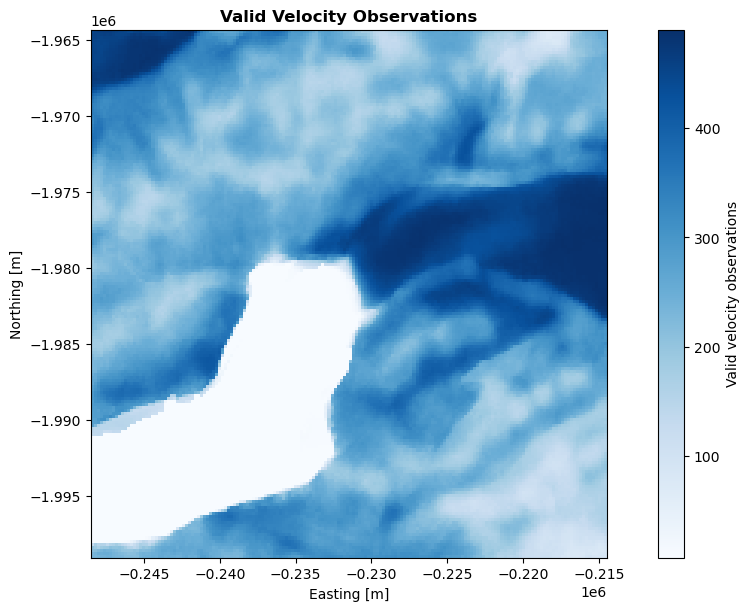

In [18]:
# prepapre velocity data for plotting
x_vals = velocity["x"].values
y_vals = velocity["y"].values

vel_band = (velocity["VelocityMap"].isel(band=2).assign_coords(x=("x", x_vals),  y=("y", y_vals),))
vel_times = pd.to_datetime(vel_band["time"].values)

# valid velocity counts
valid_count = vel_band.count(dim="time")
valid_count_plot = valid_count.where(valid_count > 0) #set 0 count to grey -- have it act as a NaN

# plotting properties for this variable
vprops = varprops["valid_count"]

# plot all time steps
fig, ax = plt.subplots(figsize=(8,6),constrained_layout=True,)
valid_count_plot.plot(ax=ax, x="x", y="y", cmap=vprops["cmap"], add_colorbar=True, cbar_kwargs={"label": vprops["label"]})
ax.set_title("Valid Velocity Observations", fontweight=plotprops["titleweight"])
ax.set_xlabel(plotprops["xlabel"], )
ax.set_ylabel(plotprops["ylabel"])
ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
ax.set_aspect("equal")


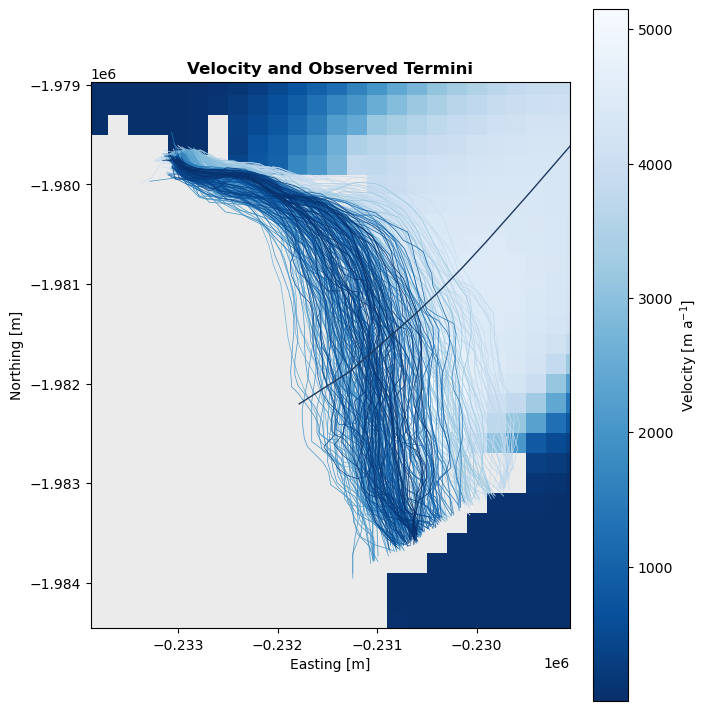

In [19]:
# prepare velocity data for plotting
x_vals = velocity["x"].values
y_vals = velocity["y"].values

vel_band = (velocity["VelocityMap"].isel(band=2).assign_coords(x=("x", x_vals),y=("y", y_vals),))
vel_times = pd.to_datetime(vel_band["time"].values)

# choose representative time index
sampletime = 300
vel_slice = vel_band.isel(time=sampletime)
sample_date = vel_times[sampletime]

# shorthand plotting properties
vprops = varprops["velocity"]
tprops = dataprops["terminus"]
clprops = dataprops["centerline"]
vel_cmap = vprops["cmap"].copy()
vel_cmap.set_bad(c_nan)
terminus_plot = terminus.sort_values("Date").copy()
date_norm = colors.Normalize(vmin=terminus_plot["Date"].min().value,vmax=terminus_plot["Date"].max().value,)
terminus_cmap = tprops["cmap"]

# plot velocity map with observed termini and extended centerline
fig, ax = plt.subplots(figsize=(7,7),constrained_layout=True,)
# velocity map
vel = vel_slice.plot(ax=ax, x="x", y="y", cmap=vel_cmap, add_colorbar=True,cbar_kwargs={"label": vprops["label"]},)
# observed termini, coloured by date
for _, row in terminus_plot.iterrows():
    color = terminus_cmap(date_norm(row["Date"].value))
    gpd.GeoSeries([row.geometry],crs=terminus.crs,).plot(ax=ax,color=color,linewidth=tprops["linewidth"],linestyle=tprops["linestyle"])
# extended centerline
centerline.plot(ax=ax,color=clprops["color"],linewidth=clprops["linewidth"],linestyle=clprops["linestyle"],)

# zoom
xmin, ymin, xmax, ymax = terminus.total_bounds
zoom = 500
ax.set_xlim(xmin - zoom, xmax + zoom)
ax.set_ylim(ymin - zoom, ymax + zoom)
ax.set_aspect("equal")

ax.set_title(f"Velocity and Observed Termini", fontweight=plotprops["titleweight"])
ax.set_xlabel(plotprops["xlabel"])
ax.set_ylabel(plotprops["ylabel"])
ax.ticklabel_format(axis="both", style="sci", scilimits=plotprops["map_scilimits"])
plt.show()

### Step 1: Finding centerline and terminus intersection 

In [20]:
# finding the intersection between the centerline and the terminus
def intersection(centerline, terminus_line):
    intersect = centerline.intersection(terminus_line)

    if intersect.is_empty:
        return None

    if intersect.geom_type == "MultiPoint": #if there is more than one intersect put the point closes to the center of the terminus line
        return min(intersect.geoms, key = lambda p: p.distance(terminus_line.centroid))
    
    return intersect
 
pts = []
for i in range(len(terminus)):
    terminus_line = terminus.geometry.iloc[i]
    pt = intersection(centerline_shape, terminus_line) #geometric intersection between centerline_shape and terminus_line 
    pts.append(pt)

terminus["intersect_points"] = pts

#check to see how many are NaN (i.e. no valid intersection)
none_vals = terminus["intersect_points"].isna().sum()
print(f"Number of NaN intersection points: {none_vals}")

#check to see how many are non NaN (i.e. valid intersection)
valid_vals = terminus["intersect_points"].notna().sum()
print(f"Number of valid intersection points: {valid_vals} out of {len(terminus)}")


Number of NaN intersection points: 0
Number of valid intersection points: 358 out of 358


### Step 2: Sample velocity at X m away from the intersection
- Using a consistent simple velocity extraction method
- As a comparison add a list that is velocity at intersection
- __Edit: If NaN at 1500m, then sample at 2000m, if still NaN then skip__

In [21]:
upstream_m = 1500

vel_at_intersection = []
vel_up_centerline = []

for i in range(len(terminus)):
    pt = terminus["intersect_points"].iloc[i]
    t_term = pd.to_datetime(terminus["Date"].iloc[i])

    if pt is None:
        vel_at_intersection.append(np.nan)
        vel_up_centerline.append(np.nan)
        continue

    vel_slice = vel_band.sel(time=t_term, method="nearest")

    # velocity at intersection
    v0 = vel_slice.sel(x=pt.x, y=pt.y, method="nearest").values
    vel_at_intersection.append(float(v0) if np.isfinite(v0) else np.nan)

    # velocity upstream along the same extended centerline
    d0 = centerline_shape.project(pt)

    v1 = np.nan

    for upstream_m in [1500, 2000]:
        d1 = d0 + upstream_m

        if d1 > centerline_shape.length:
            continue
        p1 = centerline_shape.interpolate(float(d1))
        v_test = vel_slice.sel(x=p1.x,y=p1.y,method="nearest").values

        if np.isfinite(v_test):
            v1 = float(v_test)
            break
    vel_up_centerline.append(v1)

terminus["vel_at_intersection"] = vel_at_intersection
terminus["vel_up_centerline"] = vel_up_centerline


print(f"Number of valid values in vel_at_intersection: {terminus['vel_at_intersection'].notna().sum()} out of {len(terminus)}")
print(f"Number of valid values in vel_up_centerline: {terminus['vel_up_centerline'].notna().sum()} out of {len(terminus)}")

Number of valid values in vel_at_intersection: 81 out of 358
Number of valid values in vel_up_centerline: 340 out of 358


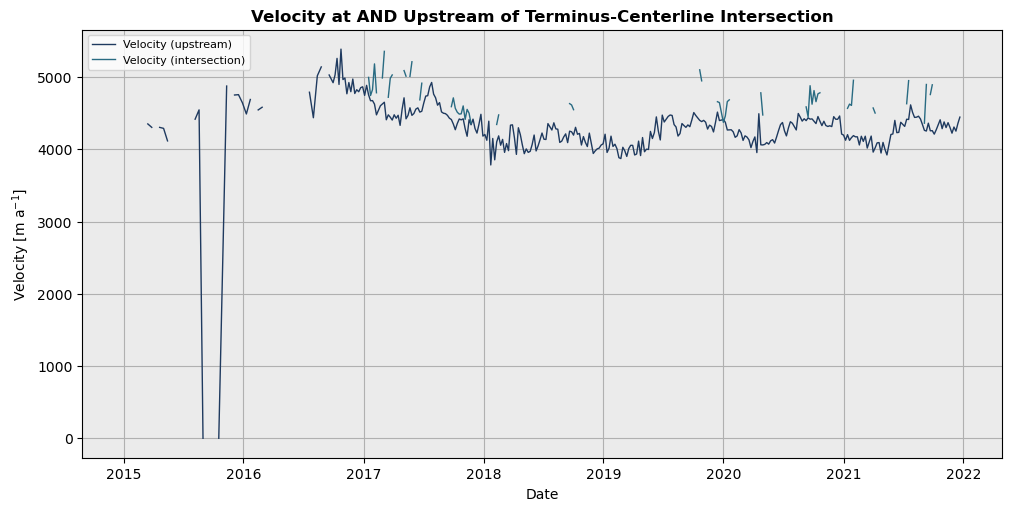

In [22]:
# plot velocity at intersection versus. upstream

# shorthand plotting properties
vprops = varprops["velocity"]
dprops = dataprops["velocity"]

fig, ax = plt.subplots(figsize=(10,5), constrained_layout=True)

# velocity upstream
ax.plot(terminus["Date"], terminus["vel_up_centerline"], label="Velocity (upstream)", color=dprops["color"], linestyle=dprops["linestyle"], linewidth=plotprops["linewidth"])
# velocity at terminus-centerline intersection
ax.plot(terminus["Date"], terminus["vel_at_intersection"], label="Velocity (intersection)", color="#296B82", linestyle="solid", linewidth=plotprops["linewidth"])
ax.set_xlabel("Date")
ax.set_ylabel(vprops["label"])
ax.set_title("Velocity at AND Upstream of Terminus-Centerline Intersection", fontweight = "bold")
ax.set_facecolor(plotprops["facecolor"])
ax.grid(plotprops["grid"])
ax.legend(fontsize=plotprops["legendsize"])
plt.show()

For each terminus position:
1. Use the centerline-terminus intersection point
2. Get the length of the upstream segment 

This is Taryn's code - slightly modified

In [23]:
def get_centerline_length(terminus, centerline):
    # ensure terminus data type
    if type(terminus) is LineString:
        pass
    if type(terminus) is pd.Series: #if pd take intersection point (from row)
        pt = terminus["intersect_points"]
    elif type(terminus) is gpd.GeoSeries: # if geoseries take single intersection point (from row)
        pt = terminus["intersect_points"].item()
    else: #if else assume it's already a point geometry
        pt = terminus

#same as tayrns code 
    if type(centerline) is LineString:
        pass
    elif type(centerline) is pd.Series:
        centerline_extended = centerline.geometry
    elif type(centerline) is gpd.GeoSeries:
        centerline = centerline.item()

    if pt is None: #if no valid intersection point return nan
        return np.nan
    
    try:
        d = centerline.project(pt) #distance along the centreline from start to the intersection point
        centerline_length = centerline.length - d

    except:
        centerline_length = np.nan #if anything fails (bad geometry, etc.) return nan

    return centerline_length

# calculate glacier length at centerline for each terminus
terminus["Centerline_Length"] = terminus.apply(get_centerline_length, axis = 1, centerline=centerline_shape)
terminus = terminus[terminus["Centerline_Length"].notna()].copy()

# use the first valid terminus as a baseline
terminus["Centerline_Length"] -= terminus["Centerline_Length"].iloc[0]

Calculating the difference between expected position (L_expected) and observed position (L):
- Using the the centerline length calculate the expected position based on the previous position
    - i.e., Expected position at time (t) based on the previous position + previous velocity (v) * elapsed time (dt)

In [24]:
# observed terminus position
terminus["L"] = terminus["Centerline_Length"]

# time step
terminus["dt_days"] = terminus["Date"].diff().dt.days
terminus["dt_years"] = terminus["dt_days"] / 365.25

# observed change in terminus position
terminus["dL"] = terminus["L"].diff()
terminus["dLdt"] = terminus["dL"] / terminus["dt_years"]

# expected position at t based on previous position + previous velocity * elapsed time
terminus["L_expected"] = (terminus["L"].shift(1) + terminus["vel_up_centerline"].shift(1) * terminus["dt_years"])

# difference between expected and observed position
terminus["expected_minus_observed"] = terminus["L_expected"] - terminus["L"]

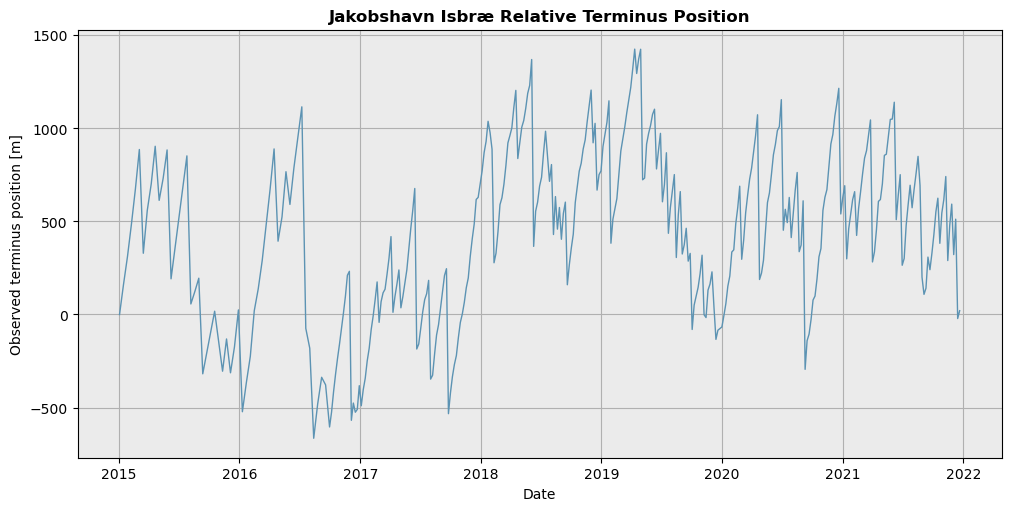

In [25]:
# relative terminus position through time

# shorthand plotting properties
tprops = varprops["observed_terminus_position"]

fig, ax = plt.subplots(figsize=(10,5),constrained_layout=True)
ax.plot(terminus["Date"], terminus[tprops["variable_name"]], linewidth=plotprops["linewidth"], color ="#5c93b3" )
ax.set_title("Jakobshavn Isbræ Relative Terminus Position", weight ="bold")
ax.set_xlabel("Date")
ax.set_ylabel(tprops["label"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(plotprops["grid"])
plt.show()

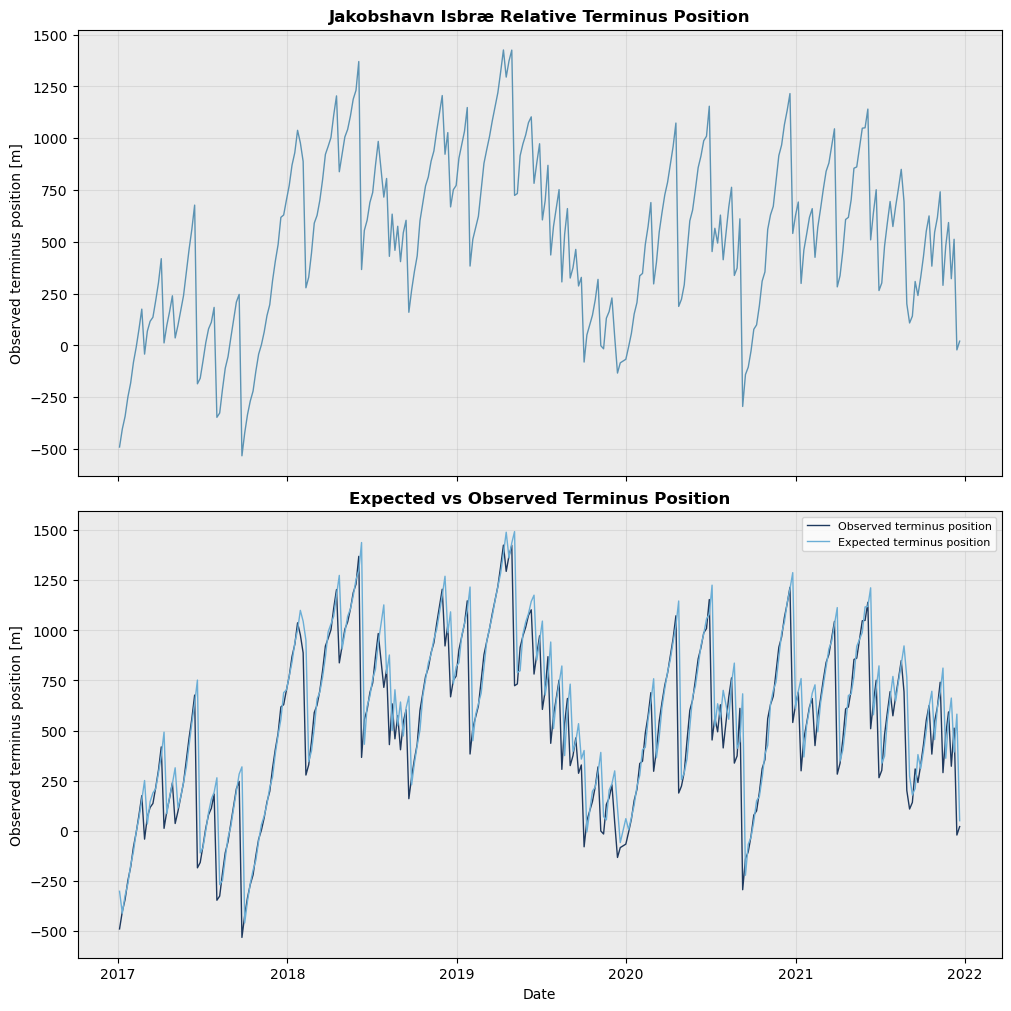

In [26]:
# relative terminus positions and observed vs. predicted

# shorthand plotting properties
tprops = varprops["observed_terminus_position"]
exprops = varprops["expected_terminus_position"]

# cut to 2017 because of limited velocity data before then
terminus_plot = terminus[terminus["Date"] >= "2017"].copy()

fig, ax = plt.subplots(2,1, figsize=(10, 10), constrained_layout=True, sharex=True)

# jakobshavn relative terminus posotion
ax[0].plot(terminus_plot["Date"], terminus_plot[tprops["variable_name"]], linewidth=plotprops["linewidth"], color="#5c93b3")
ax[0].set_title("Jakobshavn Isbræ Relative Terminus Position", fontweight = "bold")
ax[0].set_ylabel(tprops["label"])
ax[0].set_facecolor(plotprops["facecolor"])
ax[0].grid(plotprops["grid"], alpha=0.3)

# expected vs observed terminus position
ax[1].plot(terminus_plot["Date"], terminus_plot[tprops["variable_name"]], linewidth=plotprops["linewidth"], color="#1f3a5f",label=tprops["name"].capitalize())
ax[1].plot(terminus_plot["Date"],terminus_plot[exprops["variable_name"]],linewidth=plotprops["linewidth"],color="#6baed6",label=exprops["name"].capitalize())
ax[1].set_title("Expected vs Observed Terminus Position", fontweight = "bold")
ax[1].set_xlabel("Date")
ax[1].set_ylabel(tprops["label"])
ax[1].set_facecolor(plotprops["facecolor"])
ax[1].grid(plotprops["grid"], alpha=0.3)
ax[1].legend(fontsize=plotprops["legendsize"])
plt.show()

Calculate the magnitude of calving events, where __calving = velocity x dt - dL__

__Calving events are positive__:
- dLdt > 0 means length is increasing with time - i.e., advance 
- dLdT < 0 means length is decreasing with time - i.e., retreat
    - according to plot dLdt is primarily negative
- vel > 0 flowing towards terminus 

So calving = positve value - negative value, therefore, __calving is positive__ 

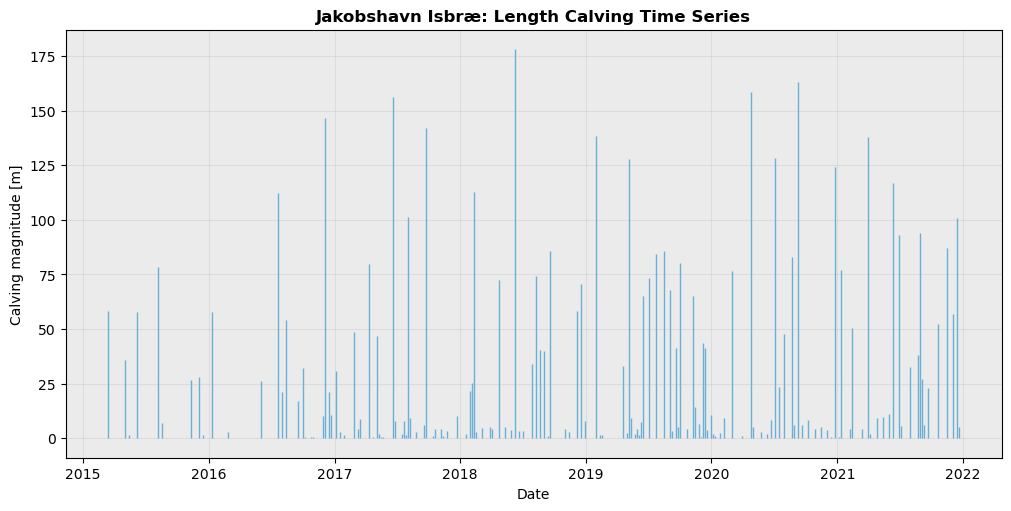

In [27]:
terminus["calving"] = terminus["vel_up_centerline"] - terminus["dLdt"]
terminus["calving_magnitude"] = terminus["calving"]/365.25

#calving time series

# shorthand plotting properties
cprops = varprops["calving_length"]

# mask negative values
terminus["calving_positive"] = (terminus["calving_magnitude"].where(terminus["calving_magnitude"] > 0))

# plot calving magnitudes
fig, ax = plt.subplots(figsize=(10,5),constrained_layout=True)
ax.vlines(terminus["Date"],ymin=0,ymax=terminus["calving_positive"],linewidth=plotprops["linewidth"],color="#6baed6")
ax.set_title("Jakobshavn Isbræ: Length Calving Time Series", fontweight = "bold")
ax.set_xlabel("Date")
ax.set_ylabel(cprops["label"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(plotprops["grid"], alpha=0.25)
plt.show()

In [28]:
calving_time_series= terminus[["Date", "vel_up_centerline","dLdt","calving","calving_magnitude","dt_days","dt_years", "Centerline_Length"]].copy()
output_path = "/Users/sofiasuhinin/Desktop/GrIS_Calving/Jakobshavn-Isbrae-CalvingStatistics/store_calving_length_ts.csv"
calving_time_series.to_csv(output_path, index=False)

## BedMachine Ice Thickness vs. Calving

This section will focus on looking at BedMachine ice thickness along the central flowline:
1. For every 6/12-day terminus position, you can find the ice thickness and water depth (if not floating)
2. Measuring calving event size in length X as a fraction of ice thickness H - where _X/H_ is a statistical variable

If you have a ratio _X/H_ where X ~ H you can explore the relationship between these two and compare across glaciers, i.e., if ratio ~ 1 compare to not  ~ 1 - can look across locations and times

In [30]:
# set data paths
bedmachine_path = project_dir / "BedMachine/KangilliupSermia/processed/KangilliupSermiaBedMachineV7.nc"

# load
bedmachine = xr.open_dataset(bedmachine_path)

# use the extended centerline from the calving analysis
centerline = gpd.GeoDataFrame(geometry=[centerline_shape], crs="EPSG:3413")
centerline_shape = centerline_shape

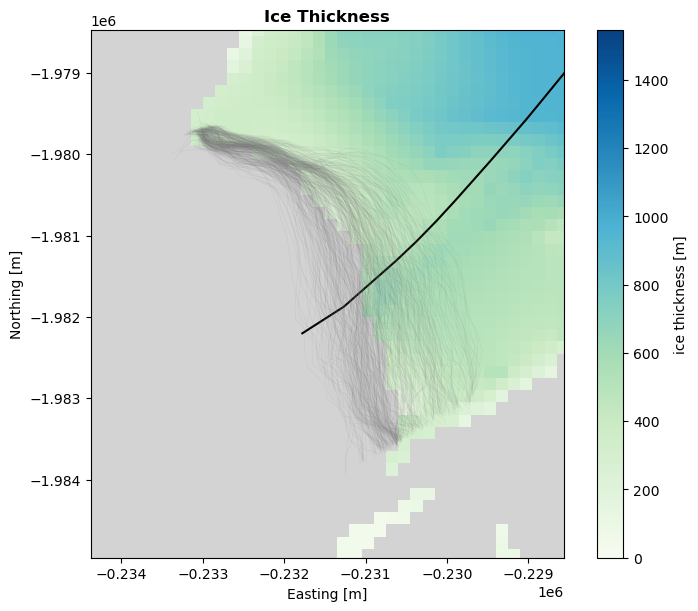

In [31]:
# plotting properties ( 0 m = grey - better for visual)
cmap = plt.colormaps["GnBu"].copy()
cmap.set_bad("lightgrey")
thickness = bedmachine["thickness"].where(bedmachine["thickness"]> 0)

fig, ax = plt.subplots(figsize=(8, 6), constrained_layout=True)

thickness.plot( ax=ax, cmap=cmap, vmin = 0)
centerline.plot(ax=ax, color = "black", linewidth = 1.5)
terminus.plot(ax = ax,color = "gray", linewidth = 0.5, alpha = 0.1)
ax.set_title("Ice Thickness", fontweight = "bold")
ax.set_xlabel("Easting [m]")
ax.set_ylabel("Northing [m]")
ax.ticklabel_format(axis="both", style="sci", scilimits=(6,6)) 

#zoom
xmin, ymin, xmax, ymax = terminus.total_bounds
zoom = 1000
ax.set_xlim(xmin - zoom, xmax + zoom)
ax.set_ylim(ymin - zoom, ymax + zoom)
ax.set_aspect("equal")

plt.show()

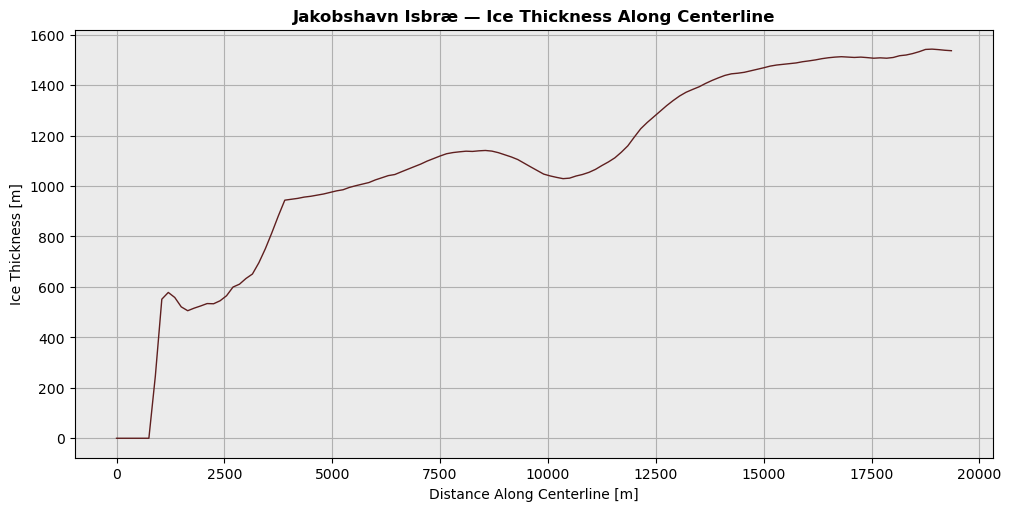

In [33]:
# sample bedmachine values along the centerline using .interp() 
    # goal to get ice thickness, bed elevation, and surface elevation along the centerline

# sample every 150 meters 
spacing = 150 # 150 m bc the BedMachine res is 150 m

# generate distances spaced every 150 m 
distances = np.arange(0, 35000, spacing)

# let these be x and y points 
points = [centerline_shape.interpolate(d)for d in distances]
x_points = np.array([point.x for point in points])
y_points = np.array([point.y for point in points])

# use nearest ice thickness to x/ypoint  - use .sel() - switched to using .interp()
thickness_centerline = bedmachine["thickness"].interp(x=xr.DataArray(x_points, dims="distance"), y=xr.DataArray(y_points, dims="distance"), method="linear")
bed_centerline = bedmachine["bed"].interp(x=xr.DataArray(x_points, dims="distance"), y=xr.DataArray(y_points, dims="distance"), method="linear")
surface_centerline = bedmachine["surface"].interp(x=xr.DataArray(x_points, dims="distance"), y=xr.DataArray(y_points, dims="distance"), method="linear")

# create profiles
thickness_profile = thickness_centerline.values
bed_profile = bed_centerline.values
surface_profile = surface_centerline.values

# surface elevation =  bed + thickness
surface_calculated = bed_profile + thickness_profile

bedmachine_profile = pd.DataFrame({
    "distance_m": distances,
    "x": x_points,
    "y": y_points,
    "thickness_m": thickness_profile,
    "bed_m": bed_profile,
    "surface_m": surface_profile,
    "surface_calculated_m": surface_calculated
})

fig, ax = plt.subplots(figsize = (10,5), constrained_layout = True)
ax.plot(bedmachine_profile["distance_m"], bedmachine_profile["thickness_m"], color="#5f1f1f", linewidth = plotprops["linewidth"])
ax.set_xlabel("Distance Along Centerline [m]")
ax.set_ylabel("Ice Thickness [m]")
ax.set_title("Jakobshavn Isbræ — Ice Thickness Along Centerline", fontweight=plotprops["titleweight"])
ax.set_facecolor(plotprops["facecolor"])
ax.grid(True)
plt.show()

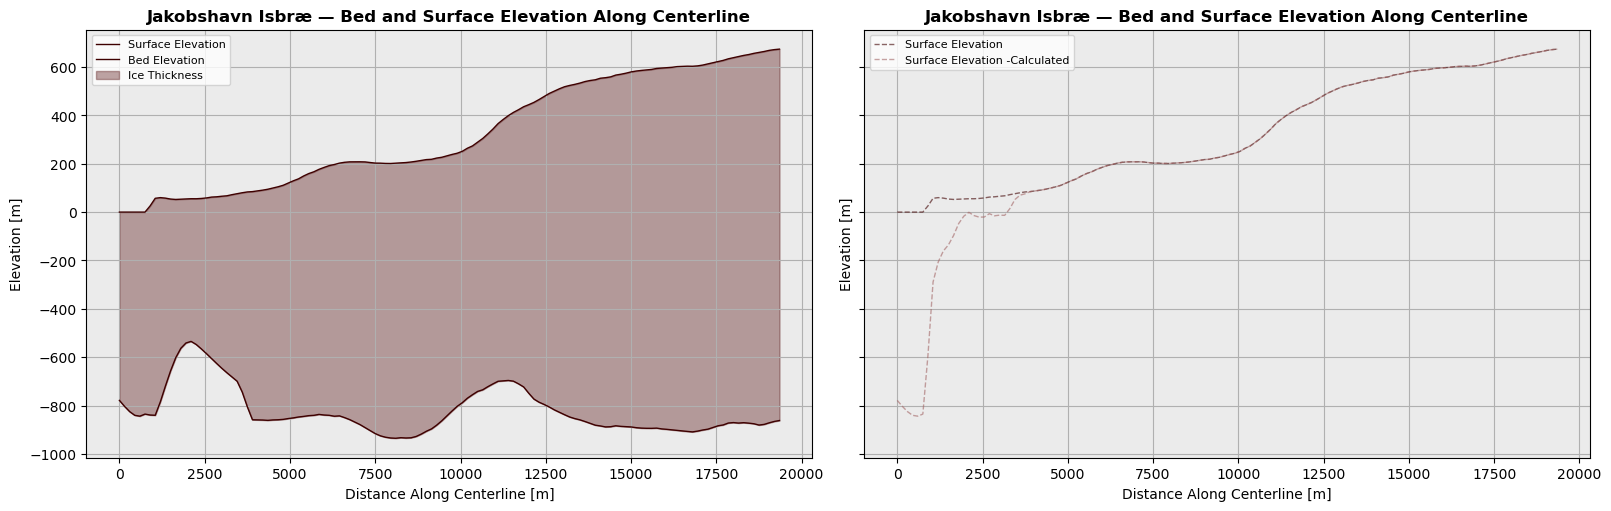

In [35]:
fig, ax = plt.subplots(1,2, figsize = (16,5), constrained_layout = True, sharex = True, sharey= True)


# plot 1 bed & surface elevation, and then fill would be thickness
# bed elevation + thickness = surface elevation
ax[0].plot(bedmachine_profile["distance_m"], bedmachine_profile["surface_m"], color="#3e0000", linewidth = plotprops["linewidth"], label="Surface Elevation")
ax[0].plot(bedmachine_profile["distance_m"], bedmachine_profile["bed_m"], color="#3e0000", linewidth = plotprops["linewidth"], label="Bed Elevation")
ax[0].fill_between(bedmachine_profile["distance_m"], bedmachine_profile["bed_m"], bedmachine_profile["surface_m"], color="#5f1f1f", alpha=0.4, label="Ice Thickness")

# plot 2 would be comparing observed surface elevation vs calculated surface elevation (bed + thickness)
ax[1].plot(bedmachine_profile["distance_m"], bedmachine_profile["surface_m"], color="#3e0000", linewidth = plotprops["linewidth"], linestyle = "--", alpha = 0.6, label = "Surface Elevation")
ax[1].plot(bedmachine_profile["distance_m"], bedmachine_profile["surface_calculated_m"], color="#a36666", linewidth = plotprops["linewidth"], linestyle = "--",alpha = 0.6, label = "Surface Elevation -Calculated")


for a in ax:
    a.set_xlabel("Distance Along Centerline [m]")
    a.set_ylabel("Elevation [m]")
    a.set_facecolor(plotprops["facecolor"])
    a.grid(True)
    a.legend(fontsize=plotprops["legendsize"])
    a.set_title("Jakobshavn Isbræ — Bed and Surface Elevation Along Centerline", fontweight=plotprops["titleweight"])

In [36]:
# change intersect_points from string to shapely points (better for geospatial)
terminus["intersect_points"] = terminus["intersect_points"].apply(lambda p: wkt.loads(p) if isinstance(p, str) else p)
print(type(terminus["intersect_points"].iloc[0]))

# get intersection coordinates
x_points = [p.x for p in terminus["intersect_points"]]
y_points = [p.y for p in terminus["intersect_points"]]

# sample nearest BedMachine thickness
terminus["thickness_at_terminus"] = bedmachine["thickness"].interp(x=xr.DataArray(x_points, dims="point"), y=xr.DataArray(y_points, dims="point"), method="nearest").values

<class 'shapely.geometry.point.Point'>


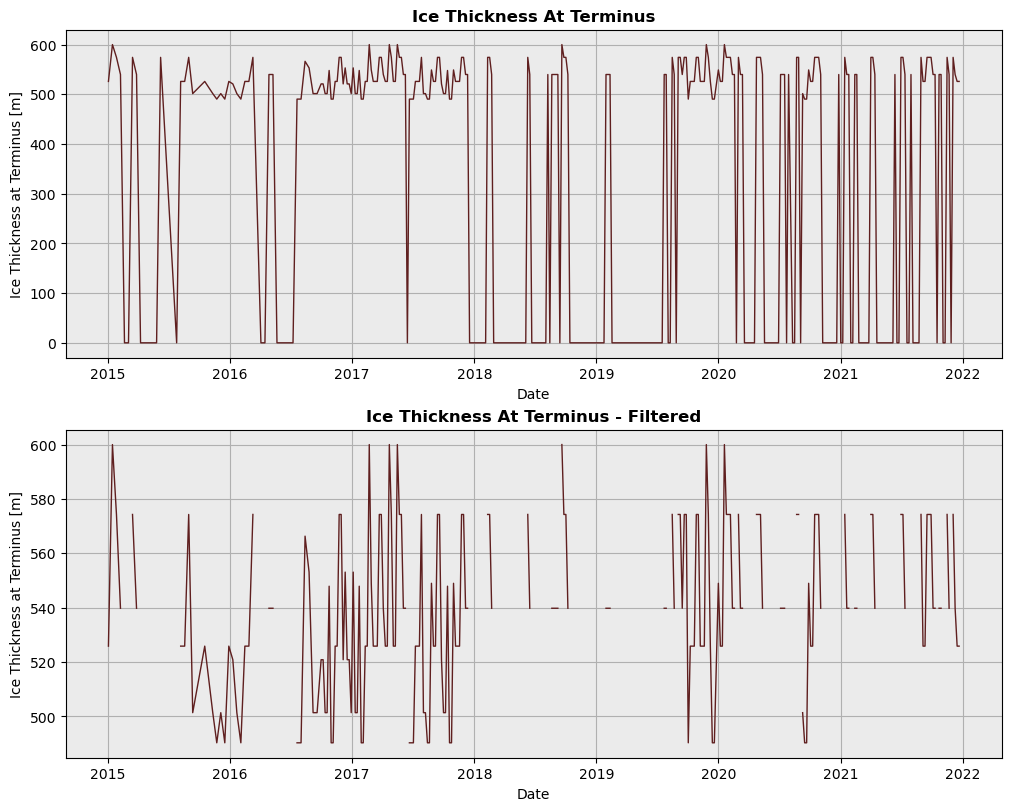

In [37]:
terminus_filtered = terminus.copy()
terminus_filtered["thickness_at_terminus"] = terminus_filtered["thickness_at_terminus"].replace(0, np.nan)

fig, ax = plt.subplots(2, 1, figsize = (10,8), constrained_layout = True)
ax[0].plot(terminus["Date"], terminus["thickness_at_terminus"], color="#5f1f1f", linewidth = plotprops["linewidth"])
ax[0].set_xlabel("Date")
ax[0].set_ylabel("Ice Thickness at Terminus [m]")
ax[0].set_title("Ice Thickness At Terminus", fontweight=plotprops["titleweight"])

ax[1].plot(terminus_filtered["Date"], terminus_filtered["thickness_at_terminus"], color="#5f1f1f", linewidth = plotprops["linewidth"])
ax[1].set_xlabel("Date")
ax[1].set_ylabel("Ice Thickness at Terminus [m]")
ax[1].set_title("Ice Thickness At Terminus - Filtered", fontweight=plotprops["titleweight"])

for a in ax.flat:
    a.set_facecolor(plotprops["facecolor"])
    a.grid(True)
plt.show()